# Validation results

This notebook reads the project's MLflow store (`mlruns/`) and compares every model setting on the
validation rows (2011–2012, 2,794 records). Nothing here trains or scores a model: the runs come from
`permits train majority`, `permits train linearsvc A|B`, `permits train curves` and
`permits train camembert pilot|main|curves`. The 2013 test set stays untouched until the pre-registered
single test run.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from geneva_permits import camembert, classical, tracking
from geneva_permits.config import FIGURES_DIR
from geneva_permits.weights import OPTIONS

pd.set_option("display.precision", 3)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
COLORS = {"none": "#2a78d6", "medium": "#eb6834", "full": "#1baf7a"}  # one hue per option
MODEL_COLORS = {"camembert": "#2a78d6", "linearsvc": "#eb6834"}

selection = tracking.runs("selection")
print(
    f"{len(selection)} runs in the selection experiment:",
    selection["params.model"].value_counts().to_dict(),
)

/home/dino/Dev/geneva-building-permit-classification/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


145 runs in the selection experiment: {'linearsvc': 132, 'camembert': 12, 'majority': 1}


## 1. Overview

**Question:** How do the three models compare on validation, and does the ranking depend on the
weighting option?

**Method:** `tracking.overview` takes the majority run, the best grid point (C, n-grams) of every
LinearSVC variant and weighting, and the mean over the three seeds of every CamemBERT weighting.
Scores are macro-F1 (the pre-registered selection metric) and accuracy on the 2,794 validation rows.

In [2]:
overview = tracking.overview(selection)
overview[["model", "variant", "weighting", "C_log2", "ngram_range", "seed", "macro_f1", "accuracy"]]

,model,variant,weighting,C_log2,ngram_range,seed,macro_f1,accuracy
0,majority,NaN,NaN,NaN,NaN,NaN,0.073,0.413
1,linearsvc,A,none,-1,1-2,NaN,0.642,0.729
2,linearsvc,A,medium,-3,1-2,NaN,0.654,0.725
3,linearsvc,A,full,-1,1-2,NaN,0.630,0.699
4,linearsvc,B,none,-1,1-2,NaN,0.657,0.739
5,linearsvc,B,medium,-3,1-2,NaN,0.661,0.735
6,linearsvc,B,full,-1,1-2,NaN,0.636,0.710
7,camembert,NaN,none,NaN,NaN,"13, 42, 73",0.703,0.760
8,camembert,NaN,medium,NaN,NaN,"13, 42, 73",0.690,0.752
9,camembert,NaN,full,NaN,NaN,"13, 42, 73",0.684,0.747


**Finding:** The majority baseline (always REN) reaches macro-F1 0.073 at 41% accuracy. The best
LinearSVC setting is variant B with medium weighting, C = 2⁻³ and uni+bigrams at 0.661; the best
CamemBERT setting is no weighting at 0.703 (mean of three seeds, 0.695–0.714). CamemBERT leads by
4.2 points of macro-F1 and 2.5 points of accuracy. All LinearSVC settings lie between 0.630 and
0.661 and all CamemBERT settings between 0.684 and 0.703, so the gap between the models is larger
than any gap between settings of one model.

## 2. Class weighting

**Question:** Does weighting the rare classes raise macro-F1, and what happens to AFF, the rarest
class (437 training rows, 30 validation rows)?

**Method:** Macro-F1 and AFF F1 per weighting option from the overview table. The options are
none, medium (square root of the balanced weights, rescaled to mean 1 per row) and full
(n / (K·n_c)); both models receive the same per-row weights (config.yaml `weighting`).

In [3]:
weighting = overview.dropna(subset=["weighting"]).assign(variant=lambda t: t["variant"].fillna("-"))
weighting.pivot(index=["model", "variant"], columns="weighting", values=["macro_f1", "f1_AFF"])

macro_f1               f1_AFF              
weighting             none medium   full   none medium   full
model     variant                                            
linearsvc A          0.642  0.654  0.630  0.328  0.388  0.350
          B          0.657  0.661  0.636  0.357  0.374  0.343
camembert -          0.703  0.690  0.684  0.485  0.445  0.412

**Finding:** Weighting lowers CamemBERT's macro-F1 step by step (0.703, 0.690, 0.684) and gives
LinearSVC at most 1.2 points at medium (A: 0.642 → 0.654, B: 0.657 → 0.661), while full weighting
costs both variants 1–2 points. The rare class does not profit either: CamemBERT's AFF F1 falls from
0.485 to 0.445 and 0.412 as the weight grows, and LinearSVC's AFF F1 moves by a few points in
either direction (A 0.33 / 0.39 / 0.35, B 0.36 / 0.37 / 0.34). The weights buy AFF recall at the
cost of precision on the frequent classes, and the net effect on macro-F1 is zero or negative.
"None" won for CamemBERT under the pre-registered rule (best mean macro-F1 over the seeds); the
margins, 1.3 and 1.9 points, are of the same order as the spread between its three seeds
(1.9 points).

## 3. Preprocessing: variant A vs B

**Question:** Does lemmatization with stop-word removal (variant B) beat the raw text (variant A)
for TF-IDF + LinearSVC?

**Method:** Best grid point per variant and weighting from the overview. The grid is
C = 2⁻⁵ … 2¹⁵ in steps of 2² times {unigrams, uni+bigrams}, with the two-step extension when the
best C sits on an edge.

In [4]:
linearsvc = overview[overview["model"].eq("linearsvc")].set_index(["weighting", "variant"])
linearsvc[["C_log2", "ngram_range", "macro_f1", "accuracy"]].unstack("variant")

C_log2     ngram_range      macro_f1        accuracy       
variant        A   B           A    B        A      B        A      B
weighting                                                            
none          -1  -1         1-2  1-2    0.642  0.657    0.729  0.739
medium        -3  -3         1-2  1-2    0.654  0.661    0.725  0.735
full          -1  -1         1-2  1-2    0.630  0.636    0.699  0.710

**Finding:** Variant B beats A at every weighting, by 0.6 to 1.5 points of macro-F1 (none 0.657 vs
0.642, medium 0.661 vs 0.654, full 0.636 vs 0.630) and by about one point of accuracy. Both
variants choose uni+bigrams at every weighting, and the best C is 2⁻³ at medium and 2⁻¹ otherwise,
well inside the grid, so no extension was needed on the full training set. Lemmatization helps a
little; the choice of weighting matters about as much.

## 4. Per-class scores and confusion matrices

**Question:** Where do the selected models fail, and do they fail on the same classes?

**Method:** `classical.selected()` and `camembert.selected()` apply the pre-registered rules. The
per-class table and the confusion matrix of the LinearSVC run are its logged artifacts; CamemBERT's
are the mean over its three seeds, so the counts are fractional. Rows are true labels, columns
predictions.

In [5]:
variant, weighting = classical.selected()
svc_runs = tracking.best(
    selection[selection["params.model"].eq("linearsvc")], ["variant", "weighting"]
)
svc_run = svc_runs.set_index(["params.variant", "params.weighting"]).loc[(variant, weighting)]
main = selection[selection["params.model"].eq("camembert") & selection["params.stage"].eq("main")]
bert_runs = main[main["params.weighting"].eq(camembert.selected())]
c_log2, ngrams = svc_run["params.C_log2"], svc_run["params.ngram_range"]
print(f"LinearSVC {variant} / {weighting}, C = 2^{c_log2}, n-grams {ngrams}")
print(f"CamemBERT {camembert.selected()}, seeds {sorted(bert_runs['params.seed'])}")

per_class = {
    "LinearSVC": tracking.table(svc_run["run_id"], "per_class.json"),
    "CamemBERT": tracking.mean_table(bert_runs["run_id"], "per_class.json"),
}
pd.concat(per_class, axis=1)

LinearSVC B / medium, C = 2^-3, n-grams 1-2
CamemBERT none, seeds ['13', '42', '73']


LinearSVC                       CamemBERT                      
      precision recall     f1 support precision recall     f1 support
class                                                                
AFF       0.279  0.567  0.374      30     0.434  0.556  0.485    30.0
AGR       0.568  0.721  0.635     122     0.574  0.680  0.623   122.0
AGV       0.530  0.628  0.575     113     0.606  0.788  0.685   113.0
EQU       0.711  0.697  0.704     350     0.758  0.729  0.742   350.0
NOU       0.581  0.713  0.640     136     0.688  0.676  0.680   136.0
PI        0.699  0.624  0.659     670     0.683  0.675  0.679   670.0
REN       0.832  0.797  0.814    1155     0.846  0.811  0.828  1155.0
VIL       0.865  0.908  0.886     218     0.895  0.917  0.906   218.0

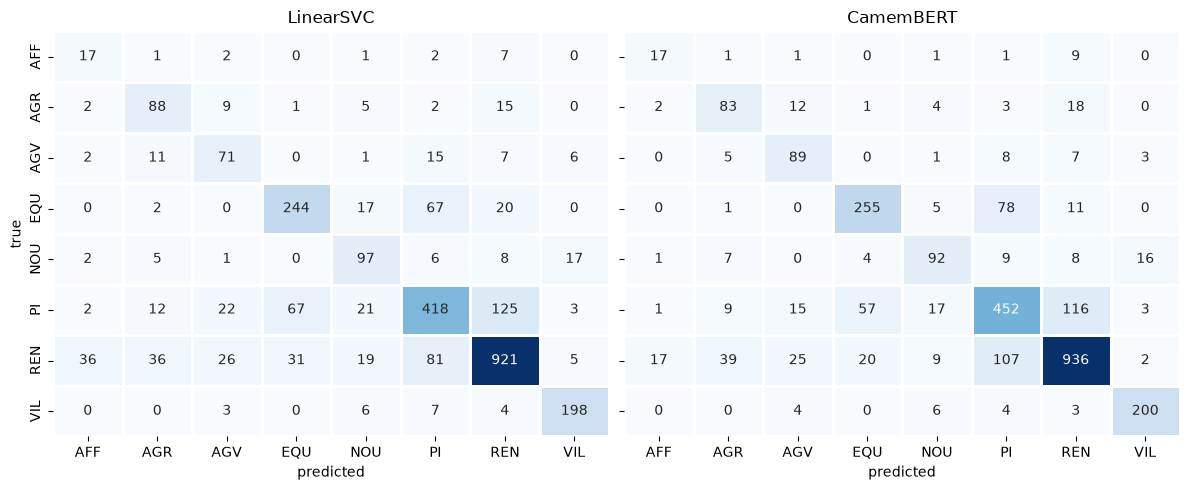

In [6]:
confusion = {
    "LinearSVC": tracking.table(svc_run["run_id"], "confusion.json"),
    "CamemBERT": tracking.mean_table(bert_runs["run_id"], "confusion.json"),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (name, matrix) in zip(axes, confusion.items(), strict=True):
    sns.heatmap(matrix, annot=True, fmt=".0f", cmap="Blues", cbar=False, linewidths=1, ax=ax)
    ax.set(title=name, xlabel="predicted", ylabel="true" if ax is axes[0] else "")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "confusion_validation.png", dpi=200)

**Finding:** AFF is the weakest class for both models (F1 0.37 and 0.49). Both find about 57% of the
30 AFF rows; the difference is precision (0.28 vs 0.43), because LinearSVC labels 36 REN rows as
AFF and CamemBERT 17. The large confusions are shared: PI predicted as REN (125 vs 116 rows), REN
predicted as PI (81 vs 107), PI and EQU in both directions (67 / 67 vs 57 / 78), and REN predicted
as AGR (36 vs 39). CamemBERT gains most on AFF and AGV (+11 points each), then NOU and EQU (+4), and
is 1.2 points behind on AGR. VIL, REN and EQU are the three best classes for both models, AFF the
worst.

## 5. CamemBERT training curves

**Question:** How does validation macro-F1 evolve over the ten epochs, and which epoch did the
best-epoch rule keep?

**Method:** `val_macro_f1` is logged after every epoch of the nine main runs and
`tracking.histories` lines the runs up. The kept epoch is the first one with the highest value;
the dots mark it. The learning-rate schedule (10% warmup, linear decay) always runs over all ten
epochs, so the kept epoch only decides which weights were stored.

params.seed,13,42,73
params.weighting,,,
none,5,3,1
medium,5,9,8
full,10,9,5


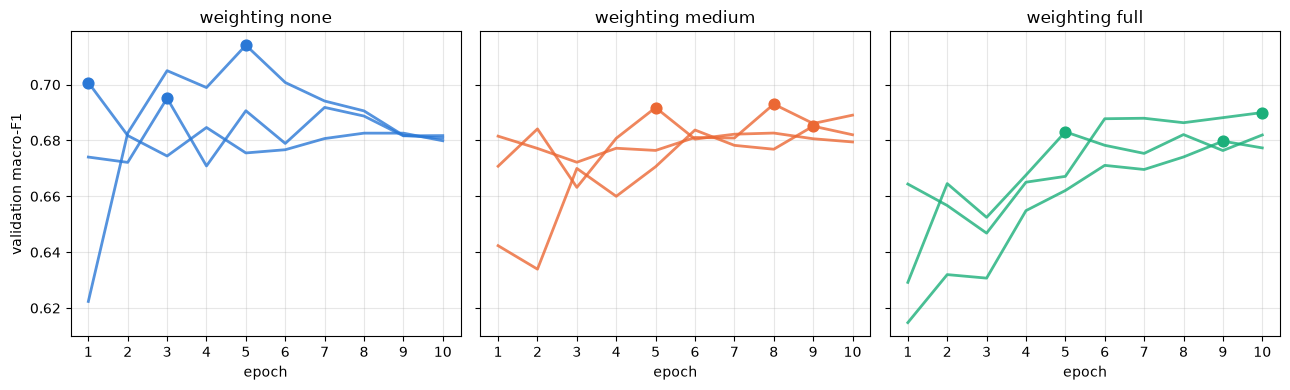

In [7]:
epochs = tracking.histories(main, "val_macro_f1", ["weighting", "seed"])
kept = main.pivot(index="params.weighting", columns="params.seed", values="metrics.kept_epoch")
kept = kept.reindex(OPTIONS).astype(int)
display(kept)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, option in zip(axes, OPTIONS, strict=True):
    for seed in sorted(epochs[option].columns):
        series = epochs[(option, seed)]
        ax.plot(series.index, series, color=COLORS[option], alpha=0.8, lw=2)
        ax.scatter(
            kept.loc[option, seed],
            series[kept.loc[option, seed]],
            color=COLORS[option],
            s=60,
            zorder=3,
        )
    ax.set(title=f"weighting {option}", xlabel="epoch", xticks=range(1, 11))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("validation macro-F1")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "camembert_epochs.png", dpi=200)

**Finding:** Every run is between 0.62 and 0.71 after the first epoch and then moves within a band
of about two points, while the training loss keeps falling (logged as `train_loss`): the later
epochs fit the training rows without changing the validation score. The kept epochs are spread
accordingly: 5, 3 and 1 without weighting (seed 73 peaked at 0.701 after one epoch and stayed near
0.68 afterwards), 5 to 10 for the weighted runs, whose curves rise more slowly. Nothing suggests
that more epochs would help. The best-epoch rule mainly protects the unweighted runs against the
1–3 point decline they show after their peak.

## 6. Learning curves

**Question:** How much does each model gain from more training data, and does the gap between the
models depend on the training size?

**Method:** `tracking.learning_curves` joins the best retuned LinearSVC point per draw (C and
n-grams retuned, weighting fixed) with the CamemBERT runs at the selected weighting and learning
rate, on the same nested draws (10% ⊂ 30% ⊂ 100%, seeds 13, 42 and 73). The full set is drawn once
for LinearSVC and is the three main runs for CamemBERT. Points are single draws, the lines join
the means, and the x-axis is logarithmic in the number of training rows.

mean                 min                 max  \
model               camembert linearsvc camembert linearsvc camembert   
fraction train_rows                                                     
0.1      3078           0.659     0.626     0.647     0.621     0.668   
0.3      9235           0.690     0.652     0.686     0.647     0.693   
1.0      30782          0.703     0.661     0.695     0.661     0.714   

                               
model               linearsvc  
fraction train_rows            
0.1      3078           0.634  
0.3      9235           0.659  
1.0      30782          0.661

params.seed,13,42,73
params.fraction,,,
0.1,10.0,10.0,7.0
0.3,5.0,5.0,7.0


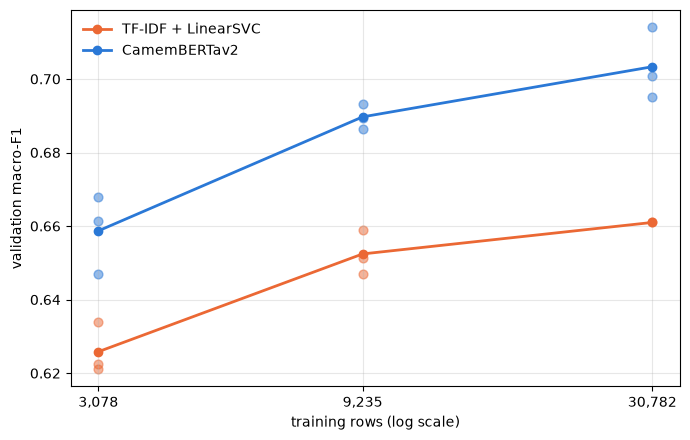

In [8]:
curves = tracking.learning_curves()
means = (
    curves.groupby(["model", "fraction", "train_rows"])["macro_f1"]
    .agg(["mean", "min", "max"])
    .reset_index()
)
display(
    means.pivot(index=["fraction", "train_rows"], columns="model", values=["mean", "min", "max"])
)
camembert_curves = tracking.runs("learning_curves", "params.model = 'camembert'")
display(
    camembert_curves.pivot(
        index="params.fraction", columns="params.seed", values="metrics.kept_epoch"
    )
)

fig, ax = plt.subplots(figsize=(7, 4.5))
for model, label in [("linearsvc", "TF-IDF + LinearSVC"), ("camembert", "CamemBERTav2")]:
    draws, line = curves[curves["model"].eq(model)], means[means["model"].eq(model)]
    ax.scatter(draws["train_rows"], draws["macro_f1"], color=MODEL_COLORS[model], alpha=0.5, s=40)
    ax.plot(
        line["train_rows"], line["mean"], color=MODEL_COLORS[model], lw=2, marker="o", label=label
    )
ax.set(xscale="log", xlabel="training rows (log scale)", ylabel="validation macro-F1")
ax.set_xticks(means["train_rows"].unique())
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.minorticks_off()
ax.grid(alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "learning_curves.png", dpi=200)

**Finding:** CamemBERT leads at every size: by 3.3 points at 10%, 3.8 at 30% and 4.2 at 100%. The
lead holds at every size (≈3–4 points). Trained on 30% of the rows (0.690) it already beats
LinearSVC on all of them (0.661), and on 10% (0.659) it matches it. From 10% to 100% CamemBERT
gains 4.5 points and LinearSVC 3.5, most of it between 10% and 30%. The 10% CamemBERT runs kept
epochs 10, 10 and 7: their curves were still rising when the fixed ten-epoch budget (970 updates)
ended, so the 10% point is a slight underestimate under the pre-registered rule. LinearSVC retuned
C on every draw; the 30% draw of seed 13 chose C = 2⁻⁵, the lower grid edge, which triggered the
two-step extension without changing the best point.

## 7. Findings

- **CamemBERTav2 is the better model on validation:** macro-F1 0.703 against 0.661 for the best
  LinearSVC and 0.073 for the majority baseline. The lead holds at every training size (≈3–4
  points).
- **Class weighting does not pay.** It lowers CamemBERT's macro-F1 (0.703, 0.690, 0.684) and its
  AFF F1 with it (0.49 to 0.41); LinearSVC gains at most 1.2 points from medium weighting. Under the
  pre-registered rules the selected settings are LinearSVC B / medium / C = 2⁻³ / uni+bigrams and
  CamemBERT without weighting.
- **Lemmatization helps the classical model a little:** variant B over A by 0.6–1.5 points; both
  variants prefer uni+bigrams.
- **AFF is the hard class for both models** (F1 0.37 and 0.49). Both find about 57% of the 30 AFF
  rows, but LinearSVC labels 36 REN rows as AFF and CamemBERT 17. The large confusions, PI↔REN and
  PI↔EQU, are shared by both models and point at the label boundaries rather than at one model.
- **CamemBERT's validation score is set within three epochs** and then drifts within two points.
  The spread between the three unweighted seeds, 1.9 points, is as large as the gap between the
  weighting options, so three seeds were necessary and the kept epochs (1, 3, 5) carry no meaning
  of their own.
- **More data helps both models,** CamemBERT slightly more (+4.5 vs +3.5 points from 10% to 100%);
  at 10% the CamemBERT runs were still improving when the fixed budget ended.
- **Caveats for the test run:** one validation split of 2,794 rows with 30 AFF rows; differences
  below about two points are within seed variation; the single 2013 test run adds dossier-clustered
  bootstrap intervals and paired differences.